# Supervised Contrastive Learning for Subject-Independent Motor Imagery EEG

## Цель

В предыдущих экспериментах основным ограничением системы оказалась
generalization на полностью unseen subjects.

На BCI Competition IV 2a strict subject-independent accuracy остаётся
примерно на уровне 58%, несмотря на использование:

- Cho transfer learning;
- CORAL;
- MMD;
- DANN.

На PhysioNet transfer learning и некоторые методы domain alignment
дали улучшение, однако эффект оказался dataset-dependent.

Поэтому следующий эксперимент меняет постановку задачи.

Вместо глобального выравнивания distributions разных subjects
мы будем явно формировать feature space, в котором EEG одного
motor-imagery класса от разных людей располагается ближе друг к другу.

---

# Идея Supervised Contrastive Learning

Для каждого EEG trial модель формирует feature representation.

В обычной классификации требуется только правильно предсказать класс:

```text
EEG → backbone → features → classifier → class
```

Supervised Contrastive Learning дополнительно задаёт структуру
feature space.

Например:

```text
A03 — left hand ─┐
A05 — left hand ─┼──→ должны находиться близко
A08 — left hand ─┘


A03 — right hand ─┐
A05 — right hand ─┼──→ другой кластер
A08 — right hand ─┘
```

Positive pairs определяются по motor-imagery class,
а не по identity subject.

Таким образом модель получает задачу:

> EEG одного движения от разных subjects должен иметь
> похожее representation.

При этом EEG разных motor-imagery classes должен
разделяться в feature space.

---

# Почему это отличается от предыдущих методов

## CORAL

CORAL пытался сделать похожими covariance matrices
feature representations разных subjects.

```text
subject A distribution
        ↕
    covariance alignment
        ↕
subject B distribution
```

## MMD

MMD минимизировал kernel distance между distributions
разных subjects.

```text
subject A distribution
        ↕
       MMD
        ↕
subject B distribution
```

## DANN

DANN пытался удалить информацию о subject identity,
обучая backbone против adversarial subject classifier.

```text
features → class classifier

features → GRL → subject classifier
```

## Supervised Contrastive Learning

Contrastive learning ставит другую цель:

```text
same motor-imagery class
across different subjects
        ↓
      closer

different classes
        ↓
      farther
```

То есть задача состоит не просто в удалении subject-specific information,
а в сохранении общей class-related structure между людьми.

---

# Loss

Модель обучается одновременно по двум функциям потерь:

```text
L = L_CE + λ_SupCon · L_SupCon
```

где:

- `L_CE` — обычный Cross Entropy classification loss;
- `L_SupCon` — supervised contrastive loss;
- `λ_SupCon` — вес contrastive component.

Для contrastive loss используются normalized feature embeddings
и temperature parameter `τ`.

---

# Роль Cho transfer

Как и в предыдущих экспериментах,
Cho2017 pretraining рассматривается как отдельный фактор.

Сравниваются:

| Model | Cho pretraining | Contrastive loss |
|---|---:|---:|
| Baseline | no | no |
| Transfer | yes | no |
| SupCon | no | yes |
| Transfer + SupCon | yes | yes |

Baseline и Transfer уже получены в предыдущем
strict subject-independent experiment.

В этом ноутбуке обучаются только:

```text
SupCon
Transfer + SupCon
```

---

# Экспериментальный протокол

Используются те же subject-independent splits,
что в предыдущих экспериментах.

## BCI Competition IV 2a

Strict Leave-One-Subject-Out:

```text
train subjects
validation subject
test subject
```

Test subject полностью отсутствует:

- в обучении classifier;
- в contrastive loss;
- в validation;
- в model selection.

## PhysioNet

Используется тот же 5-fold subject-wise protocol.

Все trials одного subject принадлежат только одному split.

Таким образом новые результаты можно напрямую сравнивать
с Baseline, Transfer, CORAL, MMD и DANN.

---

# Исследовательские вопросы

1. Улучшает ли supervised contrastive learning
   accuracy на unseen subjects?

2. Помогает ли SupCon на BCI IV 2a,
   где CORAL, MMD и DANN не дали устойчивого прироста?

3. Усиливает ли Cho pretraining contrastive learning?

4. Повторяется ли эффект на PhysioNet?

5. Позволяет ли class-aware representation learning
   приблизиться к subject-independent SOTA?

---

# Основная гипотеза

Если проблема cross-subject generalization связана с тем,
что одинаковый motor-imagery class имеет разные representations
у разных людей, то supervised contrastive loss должен
сформировать более устойчивое class-aware feature space.

Особенно интересен вариант:

```text
Cho pretrained EEGNet
        +
Supervised Contrastive Learning
```

поскольку pretraining предоставляет начальную EEG representation,
а contrastive objective может организовать её вокруг
motor-imagery classes независимо от subject identity.

---

# Литература

Основная работа по Supervised Contrastive Learning:

Khosla P. et al.  
**Supervised Contrastive Learning.**  
NeurIPS, 2020.

https://arxiv.org/abs/2004.11362

---

Базовая работа по contrastive representation learning:

Chen T. et al.  
**A Simple Framework for Contrastive Learning of Visual Representations
(SimCLR).**

https://arxiv.org/abs/2002.05709

---

Пример использования supervised contrastive learning
для cross-subject motor decoding:

**Supervised Contrastive Learning-Based Domain Generalization Network
for Cross-Subject Motor Decoding**

https://pubmed.ncbi.nlm.nih.gov/39046861/

---

# Scope

В этом ноутбуке не переобучаются:

- Baseline;
- Transfer;
- CORAL;
- MMD;
- DANN;
- denoising models.

Главная задача:

> проверить, помогает ли class-aware supervised contrastive learning
> улучшить clean subject-independent motor-imagery classification.


In [1]:
# ============================================================
# 1. IMPORTS + GLOBAL CONFIG
# ============================================================

import os
import random
import warnings

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import (
    DataLoader,
    TensorDataset
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    cohen_kappa_score
)


# ------------------------------------------------------------
# REPRODUCIBILITY
# ------------------------------------------------------------

SEED = 42


def set_seed(seed=SEED):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed()


# ------------------------------------------------------------
# DEVICE
# ------------------------------------------------------------

if torch.backends.mps.is_available():

    DEVICE = torch.device(
        "mps"
    )

elif torch.cuda.is_available():

    DEVICE = torch.device(
        "cuda"
    )

else:

    DEVICE = torch.device(
        "cpu"
    )


print(
    "Device:",
    DEVICE
)


# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

BASE_DIR = (
    "/Users/irina/Desktop/master project"
)

CHO_CHECKPOINT = os.path.join(
    BASE_DIR,
    "models_v2",
    "cho2017_binary_unified_eegnet.pt"
)


SUPCON_DIR = os.path.join(
    BASE_DIR,
    "results_v2",
    "contrastive_subject_independent"
)

SUPCON_MODEL_DIR = os.path.join(
    SUPCON_DIR,
    "models"
)

SUPCON_RESULT_DIR = os.path.join(
    SUPCON_DIR,
    "results"
)

SUPCON_PLOT_DIR = os.path.join(
    SUPCON_DIR,
    "plots"
)


for path in [
    SUPCON_DIR,
    SUPCON_MODEL_DIR,
    SUPCON_RESULT_DIR,
    SUPCON_PLOT_DIR
]:

    os.makedirs(
        path,
        exist_ok=True
    )


# ------------------------------------------------------------
# TRAINING CONFIG
# ------------------------------------------------------------

SUPCON_WEIGHT = 0.1
TEMPERATURE = 0.1

EPOCHS = 60
PATIENCE = 12

LR = 1e-3
WEIGHT_DECAY = 1e-4

BATCH_SIZE = 64


print(
    "Cho checkpoint exists:",
    os.path.exists(
        CHO_CHECKPOINT
    )
)

print(
    "Output:",
    SUPCON_DIR
)

Device: mps
Cho checkpoint exists: True
Output: /Users/irina/Desktop/master project/results_v2/contrastive_subject_independent


In [2]:
# ============================================================
# 2. COMMON HELPERS
# ============================================================

def standardize_trials(
    X,
    eps=1e-6
):

    mean = X.mean(
        axis=2,
        keepdims=True
    )

    std = X.std(
        axis=2,
        keepdims=True
    )

    return (
        (X - mean)
        /
        (std + eps)
    ).astype(
        np.float32
    )


def make_loader(
    X,
    y,
    batch_size=BATCH_SIZE,
    shuffle=False
):

    dataset = TensorDataset(

        torch.from_numpy(
            X
        ).float(),

        torch.from_numpy(
            y
        ).long()
    )

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=0
    )


@torch.no_grad()
def evaluate_classifier(
    model,
    loader
):

    model.eval()

    y_true = []
    y_pred = []


    for X, y in loader:

        X = X.to(
            DEVICE
        )

        logits = model(
            X
        )

        pred = (
            logits
            .argmax(dim=1)
            .cpu()
            .numpy()
        )

        y_true.extend(
            y.numpy()
        )

        y_pred.extend(
            pred
        )


    y_true = np.asarray(
        y_true
    )

    y_pred = np.asarray(
        y_pred
    )


    return {

        "accuracy":
            accuracy_score(
                y_true,
                y_pred
            ),

        "balanced_accuracy":
            balanced_accuracy_score(
                y_true,
                y_pred
            ),

        "macro_f1":
            f1_score(
                y_true,
                y_pred,
                average="macro"
            ),

        "kappa":
            cohen_kappa_score(
                y_true,
                y_pred
            )
    }


print(
    "Common helpers ready"
)

Common helpers ready


In [3]:
# ============================================================
# 3. EEGNET + SUPCON PROJECTION HEAD
# ============================================================

class AdaptiveAvgPoolWidth(nn.Module):

    def __init__(
        self,
        output_width=8
    ):
        super().__init__()

        self.output_width = (
            output_width
        )


    def forward(
        self,
        x
    ):

        width = x.shape[-1]

        outputs = []

        for i in range(
            self.output_width
        ):

            start = int(
                np.floor(
                    i
                    * width
                    / self.output_width
                )
            )

            end = int(
                np.ceil(
                    (i + 1)
                    * width
                    / self.output_width
                )
            )

            outputs.append(
                x[
                    ...,
                    start:end
                ].mean(
                    dim=-1,
                    keepdim=True
                )
            )


        return torch.cat(
            outputs,
            dim=-1
        )


class EEGNetSupCon(nn.Module):

    def __init__(
        self,
        n_channels=22,
        n_classes=4,
        projection_dim=128
    ):
        super().__init__()


        self.conv1 = nn.Conv2d(
            1,
            8,
            kernel_size=(1, 64),
            padding=(0, 31),
            bias=False
        )

        self.bn1 = nn.BatchNorm2d(
            8
        )


        self.depthwise = nn.Conv2d(
            8,
            16,
            kernel_size=(
                n_channels,
                1
            ),
            groups=8,
            bias=False
        )

        self.bn2 = nn.BatchNorm2d(
            16
        )


        self.pool1 = nn.AvgPool2d(
            (1, 4)
        )

        self.drop1 = nn.Dropout(
            0.35
        )


        self.conv2 = nn.Conv2d(
            16,
            32,
            kernel_size=(1, 16),
            padding=(0, 7),
            bias=False
        )

        self.bn3 = nn.BatchNorm2d(
            32
        )


        self.pool2 = nn.AvgPool2d(
            (1, 8)
        )

        self.drop2 = nn.Dropout(
            0.35
        )


        self.conv3 = nn.Conv2d(
            32,
            32,
            kernel_size=(1, 8),
            padding=(0, 3),
            bias=False
        )

        self.bn4 = nn.BatchNorm2d(
            32
        )


        self.pool3 = nn.AvgPool2d(
            (1, 4)
        )

        self.drop3 = nn.Dropout(
            0.35
        )


        self.adaptive_pool = (
            AdaptiveAvgPoolWidth(
                output_width=8
            )
        )


        # ----------------------------------------
        # normal classifier
        # ----------------------------------------

        self.fc = nn.Sequential(

            nn.Linear(
                32 * 8,
                64
            ),

            nn.GELU(),

            nn.Dropout(
                0.5
            ),

            nn.Linear(
                64,
                n_classes
            )
        )


        # ----------------------------------------
        # contrastive projection head
        # ----------------------------------------

        self.projector = nn.Sequential(

            nn.Linear(
                32 * 8,
                128
            ),

            nn.GELU(),

            nn.Linear(
                128,
                projection_dim
            )
        )


    def extract_features(
        self,
        x
    ):

        if x.ndim == 3:

            x = x.unsqueeze(
                1
            )


        x = self.conv1(x)
        x = self.bn1(x)


        x = self.depthwise(x)
        x = self.bn2(x)
        x = F.elu(x)


        x = self.pool1(x)
        x = self.drop1(x)


        x = self.conv2(x)
        x = self.bn3(x)
        x = F.elu(x)


        x = self.pool2(x)
        x = self.drop2(x)


        x = self.conv3(x)
        x = self.bn4(x)
        x = F.elu(x)


        x = self.pool3(x)
        x = self.drop3(x)


        x = self.adaptive_pool(
            x
        )


        return torch.flatten(
            x,
            start_dim=1
        )


    def forward(
        self,
        x
    ):

        features = (
            self.extract_features(
                x
            )
        )

        return self.fc(
            features
        )


    def forward_supcon(
        self,
        x
    ):

        features = (
            self.extract_features(
                x
            )
        )

        logits = self.fc(
            features
        )

        projection = (
            self.projector(
                features
            )
        )

        projection = F.normalize(
            projection,
            dim=1
        )


        return (
            logits,
            projection
        )


# ------------------------------------------------------------
# SANITY
# ------------------------------------------------------------

test_model = EEGNetSupCon(
    n_channels=22,
    n_classes=4
)

dummy = torch.randn(
    8,
    22,
    1000
)

with torch.no_grad():

    logits, projection = (
        test_model.forward_supcon(
            dummy
        )
    )


print(
    "Logits:",
    logits.shape
)

print(
    "Projection:",
    projection.shape
)

del test_model

Logits: torch.Size([8, 4])
Projection: torch.Size([8, 128])


In [4]:
# ============================================================
# 4. SUPERVISED CONTRASTIVE LOSS
# ============================================================

def supervised_contrastive_loss(
    features,
    labels,
    temperature=TEMPERATURE,
    eps=1e-8
):

    # features already normalized
    # shape: [batch, projection_dim]

    labels = labels.view(
        -1,
        1
    )


    batch_size = (
        features.shape[0]
    )


    # ----------------------------------------
    # similarity matrix
    # ----------------------------------------

    similarity = (
        features
        @ features.T
    )

    similarity = (
        similarity
        / temperature
    )


    # ----------------------------------------
    # positive mask:
    # same class
    # ----------------------------------------

    positive_mask = (
        labels
        == labels.T
    ).float()


    # remove self-comparison
    self_mask = torch.eye(
        batch_size,
        device=features.device
    )

    positive_mask = (
        positive_mask
        * (1 - self_mask)
    )


    # ----------------------------------------
    # numerical stability
    # ----------------------------------------

    logits_max = (
        similarity
        .max(
            dim=1,
            keepdim=True
        )[0]
        .detach()
    )

    logits = (
        similarity
        - logits_max
    )


    exp_logits = (
        torch.exp(logits)
        * (1 - self_mask)
    )


    log_prob = (
        logits
        -
        torch.log(
            exp_logits.sum(
                dim=1,
                keepdim=True
            )
            + eps
        )
    )


    # ----------------------------------------
    # mean over positive pairs
    # ----------------------------------------

    positives_per_sample = (
        positive_mask.sum(
            dim=1
        )
    )


    valid = (
        positives_per_sample
        > 0
    )


    mean_log_prob_positive = (
        (
            positive_mask
            * log_prob
        ).sum(
            dim=1
        )
        /
        (
            positives_per_sample
            + eps
        )
    )


    loss = (
        -mean_log_prob_positive[
            valid
        ].mean()
    )


    return loss

In [5]:
# ============================================================
# 5. SUPCON LOSS SANITY
# ============================================================

dummy_features = F.normalize(
    torch.randn(
        16,
        128
    ),
    dim=1
)

dummy_labels = torch.tensor(
    [
        0, 0, 0, 0,
        1, 1, 1, 1,
        2, 2, 2, 2,
        3, 3, 3, 3
    ]
)


loss = supervised_contrastive_loss(
    dummy_features,
    dummy_labels
)


print(
    "SupCon loss:",
    float(loss)
)

assert torch.isfinite(
    loss
)

print(
    "SupCon loss OK"
)

SupCon loss: 3.389188766479492
SupCon loss OK


In [6]:
# ============================================================
# 6. LOAD BCI + PHYSIONET SUBJECT-WISE DATA
# SAME STRICT SUBJECT-INDEPENDENT SPLITS
# ============================================================

import mne

from scipy.io import loadmat
from sklearn.model_selection import KFold


# ============================================================
# BCI IV 2a
# ============================================================

BCI_DIR = os.path.join(
    BASE_DIR,
    "BCICIV_2a_gdf"
)

BCI_LABELS_DIR = os.path.join(
    BASE_DIR,
    "true_labels"
)

BCI_SUBJECTS = [
    f"A{i:02d}"
    for i in range(1, 10)
]

BCI_EVENT_MAP = {
    "769": 0,
    "770": 1,
    "771": 2,
    "772": 3,
}


def load_bci_train_session(subject):

    num = int(
        subject.replace("A", "")
    )

    path = os.path.join(
        BCI_DIR,
        f"A{num:02d}T.gdf"
    )

    raw = mne.io.read_raw_gdf(
        path,
        preload=True,
        verbose=False
    )

    raw.pick(
        raw.ch_names[:22]
    )

    raw.filter(
        0.5,
        100.0,
        verbose=False
    )

    events, event_id = (
        mne.events_from_annotations(
            raw,
            verbose=False
        )
    )

    wanted_ids = {
        desc: code
        for desc, code
        in event_id.items()
        if desc in BCI_EVENT_MAP
    }

    epochs = mne.Epochs(
        raw,
        events,
        event_id=wanted_ids,
        tmin=0.0,
        tmax=3.996,
        baseline=None,
        preload=True,
        verbose=False
    )

    X = epochs.get_data().astype(
        np.float32
    )

    reverse_ids = {
        code: desc
        for desc, code
        in wanted_ids.items()
    }

    y = np.array(
        [
            BCI_EVENT_MAP[
                reverse_ids[event_code]
            ]
            for event_code
            in epochs.events[:, 2]
        ],
        dtype=np.int64
    )

    return X, y


def load_bci_eval_session(subject):

    num = int(
        subject.replace("A", "")
    )

    gdf_path = os.path.join(
        BCI_DIR,
        f"A{num:02d}E.gdf"
    )

    label_path = os.path.join(
        BCI_LABELS_DIR,
        f"A{num:02d}E.mat"
    )

    raw = mne.io.read_raw_gdf(
        gdf_path,
        preload=True,
        verbose=False
    )

    raw.pick(
        raw.ch_names[:22]
    )

    raw.filter(
        0.5,
        100.0,
        verbose=False
    )

    events, event_id = (
        mne.events_from_annotations(
            raw,
            verbose=False
        )
    )

    eval_code = event_id["783"]

    eval_events = events[
        events[:, 2] == eval_code
    ]

    epochs = mne.Epochs(
        raw,
        eval_events,
        event_id={
            "trial": eval_code
        },
        tmin=0.0,
        tmax=3.996,
        baseline=None,
        preload=True,
        verbose=False
    )

    X = epochs.get_data().astype(
        np.float32
    )

    y = (
        loadmat(
            label_path
        )["classlabel"]
        .reshape(-1)
        .astype(np.int64)
        - 1
    )

    return X, y


bci_subject_data = {}

for subject in BCI_SUBJECTS:

    X_T, y_T = load_bci_train_session(
        subject
    )

    X_E, y_E = load_bci_eval_session(
        subject
    )

    X = np.concatenate(
        [X_T, X_E],
        axis=0
    )

    y = np.concatenate(
        [y_T, y_E],
        axis=0
    )

    X = standardize_trials(
        X
    )

    bci_subject_data[
        subject
    ] = {
        "X": X,
        "y": y
    }


# strict LOSO splits
bci_loso_splits = []

for i, test_subject in enumerate(
    BCI_SUBJECTS
):

    val_subject = BCI_SUBJECTS[
        (i + 1)
        % len(BCI_SUBJECTS)
    ]

    train_subjects = [
        s
        for s in BCI_SUBJECTS
        if s not in {
            test_subject,
            val_subject
        }
    ]

    bci_loso_splits.append(
        {
            "fold": i + 1,
            "train_subjects":
                train_subjects,
            "val_subject":
                val_subject,
            "test_subject":
                test_subject
        }
    )


def build_bci_loso_fold(split):

    X_train = np.concatenate(
        [
            bci_subject_data[s]["X"]
            for s in split[
                "train_subjects"
            ]
        ],
        axis=0
    )

    y_train = np.concatenate(
        [
            bci_subject_data[s]["y"]
            for s in split[
                "train_subjects"
            ]
        ],
        axis=0
    )

    X_val = bci_subject_data[
        split["val_subject"]
    ]["X"].copy()

    y_val = bci_subject_data[
        split["val_subject"]
    ]["y"].copy()

    X_test = bci_subject_data[
        split["test_subject"]
    ]["X"].copy()

    y_test = bci_subject_data[
        split["test_subject"]
    ]["y"].copy()

    train_mean = float(
        X_train.mean()
    )

    train_std = float(
        X_train.std()
    )

    def norm(X):

        return (
            (
                X - train_mean
            )
            /
            (
                train_std + 1e-6
            )
        ).astype(np.float32)

    return (
        norm(X_train),
        y_train,
        norm(X_val),
        y_val,
        norm(X_test),
        y_test,
        train_mean,
        train_std
    )


# ============================================================
# PHYSIONET
# ============================================================

PHYS_CACHE_DIR = os.path.join(
    BASE_DIR,
    "results_physionet_external",
    "subject_cache_22ch"
)

PHYS_EXCLUDED = {
    "S088",
    "S092",
    "S100"
}

PHYS_SUBJECTS = [
    f"S{i:03d}"
    for i in range(1, 110)
    if f"S{i:03d}" not in PHYS_EXCLUDED
]


phys_subject_data = {}

for subject in PHYS_SUBJECTS:

    path = os.path.join(
        PHYS_CACHE_DIR,
        f"{subject}.npz"
    )

    data = np.load(
        path,
        allow_pickle=False
    )

    X = data["X"].astype(
        np.float32
    )

    y = data["y"].astype(
        np.int64
    )

    X = standardize_trials(
        X
    )

    phys_subject_data[
        subject
    ] = {
        "X": X,
        "y": y
    }


# same 5-fold subject-wise protocol
phys_subject_array = np.array(
    PHYS_SUBJECTS
)

outer_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

phys_folds = []

for fold_idx, (
    train_val_idx,
    test_idx
) in enumerate(
    outer_cv.split(
        phys_subject_array
    ),
    start=1
):

    train_val_subjects = (
        phys_subject_array[
            train_val_idx
        ].tolist()
    )

    test_subjects = (
        phys_subject_array[
            test_idx
        ].tolist()
    )

    rng = np.random.default_rng(
        SEED + fold_idx
    )

    shuffled = np.array(
        train_val_subjects
    )

    rng.shuffle(
        shuffled
    )

    n_val = max(
        1,
        int(
            round(
                0.20
                * len(shuffled)
            )
        )
    )

    val_subjects = (
        shuffled[:n_val]
        .tolist()
    )

    train_subjects = (
        shuffled[n_val:]
        .tolist()
    )

    phys_folds.append(
        {
            "fold":
                fold_idx,
            "train_subjects":
                train_subjects,
            "val_subjects":
                val_subjects,
            "test_subjects":
                test_subjects
        }
    )


def concatenate_phys_subjects(
    subjects
):

    X = np.concatenate(
        [
            phys_subject_data[s]["X"]
            for s in subjects
        ],
        axis=0
    )

    y = np.concatenate(
        [
            phys_subject_data[s]["y"]
            for s in subjects
        ],
        axis=0
    )

    return X, y


def build_phys_fold(split):

    X_train, y_train = (
        concatenate_phys_subjects(
            split["train_subjects"]
        )
    )

    X_val, y_val = (
        concatenate_phys_subjects(
            split["val_subjects"]
        )
    )

    X_test, y_test = (
        concatenate_phys_subjects(
            split["test_subjects"]
        )
    )

    train_mean = float(
        X_train.mean()
    )

    train_std = float(
        X_train.std()
    )

    def norm(X):

        return (
            (
                X - train_mean
            )
            /
            (
                train_std + 1e-6
            )
        ).astype(np.float32)

    return (
        norm(X_train),
        y_train,
        norm(X_val),
        y_val,
        norm(X_test),
        y_test,
        train_mean,
        train_std
    )


# ============================================================
# CHECK
# ============================================================

print()
print("BCI subjects:", len(bci_subject_data))
print("BCI folds:", len(bci_loso_splits))

print()
print("PhysioNet subjects:", len(phys_subject_data))
print("PhysioNet folds:", len(phys_folds))

print()
print("BCI fold 1:")
print(
    "Train:",
    bci_loso_splits[0]["train_subjects"]
)
print(
    "Val:",
    bci_loso_splits[0]["val_subject"]
)
print(
    "Test:",
    bci_loso_splits[0]["test_subject"]
)

print()
print("DATA READY")

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are n


BCI subjects: 9
BCI folds: 9

PhysioNet subjects: 106
PhysioNet folds: 5

BCI fold 1:
Train: ['A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09']
Val: A02
Test: A01

DATA READY


In [7]:
# ============================================================
# 7. CHO BACKBONE TRANSFER
# ============================================================

cho_checkpoint = torch.load(
    CHO_CHECKPOINT,
    map_location="cpu"
)


def load_cho_backbone(model):

    if (
        isinstance(cho_checkpoint, dict)
        and "model_state_dict" in cho_checkpoint
    ):
        source = cho_checkpoint[
            "model_state_dict"
        ]
    else:
        source = cho_checkpoint

    target = model.state_dict()

    transferred = {}

    for key, value in source.items():

        key = key.replace(
            "module.",
            ""
        )

        # classifier head from Cho is not transferred
        if key.startswith("fc."):
            continue

        # new SupCon projector also does not exist in Cho
        if key.startswith("projector."):
            continue

        if (
            key in target
            and target[key].shape == value.shape
        ):
            transferred[key] = value


    model.load_state_dict(
        transferred,
        strict=False
    )

    return {
        "n_transferred":
            len(transferred),
        "keys":
            list(transferred.keys())
    }


# ------------------------------------------------------------
# CHECK
# ------------------------------------------------------------

test_model = EEGNetSupCon(
    n_channels=22,
    n_classes=4
)

info = load_cho_backbone(
    test_model
)

print(
    "Transferred tensors:",
    info["n_transferred"]
)

assert (
    info["n_transferred"] == 24
), (
    "Expected 24 transferred tensors, "
    f"got {info['n_transferred']}"
)

print(
    "Cho transfer OK"
)

del test_model

Transferred tensors: 24
Cho transfer OK


In [8]:
# ============================================================
# 8. SUPCON TRAINER
# ============================================================

def train_supcon_model(
    model,
    subject_data,
    train_subjects,
    X_val,
    y_val,
    train_mean,
    train_std,
    checkpoint_path,
    domain_batch_size,
    use_transfer=False
):

    set_seed(SEED)


    # --------------------------------------------------------
    # OPTIONAL CHO PRETRAINING
    # --------------------------------------------------------

    if use_transfer:

        info = load_cho_backbone(
            model
        )

        assert (
            info["n_transferred"] == 24
        )

        print(
            "Cho transferred:",
            info["n_transferred"]
        )


    model = model.to(
        DEVICE
    )


    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LR,
        weight_decay=WEIGHT_DECAY
    )


    criterion = nn.CrossEntropyLoss()


    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    val_loader = make_loader(
        X_val,
        y_val,
        shuffle=False
    )


    # --------------------------------------------------------
    # PREPARE SUBJECT-WISE TRAIN DATA
    # --------------------------------------------------------

    train_arrays = {}

    for subject in train_subjects:

        X = (
            subject_data[
                subject
            ]["X"]
            .copy()
        )

        y = (
            subject_data[
                subject
            ]["y"]
            .copy()
        )

        X = (
            (
                X - train_mean
            )
            /
            (
                train_std + 1e-6
            )
        ).astype(
            np.float32
        )

        train_arrays[
            subject
        ] = (
            X,
            y
        )


    total_trials = sum(
        len(
            train_arrays[s][1]
        )
        for s in train_subjects
    )


    steps_per_epoch = int(
        np.ceil(
            total_trials
            /
            (
                2 * domain_batch_size
            )
        )
    )


    # --------------------------------------------------------
    # TRAINING STATE
    # --------------------------------------------------------

    best_val = -np.inf
    best_epoch = 0
    patience_counter = 0

    rng = np.random.default_rng(
        SEED
    )


    # --------------------------------------------------------
    # EPOCHS
    # --------------------------------------------------------

    for epoch in range(
        1,
        EPOCHS + 1
    ):

        model.train()

        ce_losses = []
        supcon_losses = []
        total_losses = []


        for _ in range(
            steps_per_epoch
        ):

            # two different source subjects
            s1, s2 = rng.choice(
                train_subjects,
                size=2,
                replace=False
            )


            X1, y1 = train_arrays[s1]
            X2, y2 = train_arrays[s2]


            idx1 = rng.choice(
                len(y1),
                size=domain_batch_size,
                replace=(
                    len(y1)
                    < domain_batch_size
                )
            )

            idx2 = rng.choice(
                len(y2),
                size=domain_batch_size,
                replace=(
                    len(y2)
                    < domain_batch_size
                )
            )


            # combine two subjects into one batch
            X_batch = np.concatenate(
                [
                    X1[idx1],
                    X2[idx2]
                ],
                axis=0
            )

            y_batch = np.concatenate(
                [
                    y1[idx1],
                    y2[idx2]
                ],
                axis=0
            )


            xb = torch.from_numpy(
                X_batch
            ).float().to(
                DEVICE
            )

            yb = torch.from_numpy(
                y_batch
            ).long().to(
                DEVICE
            )


            optimizer.zero_grad()


            logits, projection = (
                model.forward_supcon(
                    xb
                )
            )


            ce_loss = criterion(
                logits,
                yb
            )


            supcon_loss = (
                supervised_contrastive_loss(
                    projection,
                    yb
                )
            )


            loss = (
                ce_loss
                +
                SUPCON_WEIGHT
                * supcon_loss
            )


            loss.backward()
            optimizer.step()


            ce_losses.append(
                ce_loss.item()
            )

            supcon_losses.append(
                supcon_loss.item()
            )

            total_losses.append(
                loss.item()
            )


        # ----------------------------------------------------
        # VALIDATION — normal classification only
        # ----------------------------------------------------

        val_metrics = evaluate_classifier(
            model,
            val_loader
        )

        val_acc = val_metrics[
            "accuracy"
        ]


        if val_acc > best_val:

            best_val = val_acc
            best_epoch = epoch
            patience_counter = 0

            torch.save(
                model.state_dict(),
                checkpoint_path
            )

        else:

            patience_counter += 1


        if (
            epoch == 1
            or epoch % 5 == 0
        ):

            print(
                f"epoch {epoch:02d} | "
                f"CE={np.mean(ce_losses):.4f} | "
                f"SupCon={np.mean(supcon_losses):.4f} | "
                f"Total={np.mean(total_losses):.4f} | "
                f"val={val_acc:.4f} | "
                f"best={best_val:.4f}"
            )


        if (
            patience_counter
            >= PATIENCE
        ):

            print(
                "Early stopping"
            )

            break


    # --------------------------------------------------------
    # RESTORE BEST MODEL
    # --------------------------------------------------------

    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=DEVICE
        )
    )


    return (
        model,
        best_epoch,
        best_val
    )

In [9]:
# ============================================================
# 9. SUPCON SANITY CHECK — BCI FOLD 1
# ============================================================

# temporary
EPOCHS = 2
PATIENCE = 2

BCI_SUPCON_BATCH = 32


split = bci_loso_splits[0]


(
    X_train,
    y_train,
    X_val,
    y_val,
    X_test,
    y_test,
    train_mean,
    train_std
) = build_bci_loso_fold(
    split
)


print(
    "Train subjects:",
    split["train_subjects"]
)

print(
    "Val subject:",
    split["val_subject"]
)

print(
    "Test subject:",
    split["test_subject"]
)


set_seed(SEED)


model = EEGNetSupCon(
    n_channels=22,
    n_classes=4,
    projection_dim=128
)


sanity_checkpoint = os.path.join(
    SUPCON_MODEL_DIR,
    "SUPCON_SANITY_BCI_fold01.pt"
)


(
    model,
    best_epoch,
    best_val
) = train_supcon_model(

    model=model,

    subject_data=
        bci_subject_data,

    train_subjects=
        split["train_subjects"],

    X_val=X_val,
    y_val=y_val,

    train_mean=train_mean,
    train_std=train_std,

    checkpoint_path=
        sanity_checkpoint,

    domain_batch_size=
        BCI_SUPCON_BATCH,

    use_transfer=False
)


test_loader = make_loader(
    X_test,
    y_test,
    shuffle=False
)


test_metrics = evaluate_classifier(
    model,
    test_loader
)


print()
print(
    "Best epoch:",
    best_epoch
)

print(
    "Best val:",
    round(
        best_val,
        4
    )
)

print(
    "Test:",
    round(
        test_metrics["accuracy"],
        4
    )
)


del model

if DEVICE.type == "mps":
    torch.mps.empty_cache()

Train subjects: ['A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09']
Val subject: A02
Test subject: A01
epoch 01 | CE=1.3146 | SupCon=4.1699 | Total=1.7316 | val=0.3785 | best=0.3785

Best epoch: 1
Best val: 0.3785
Test: 0.4531



##########################################################################################
START BCI SUPCON
##########################################################################################

BCI SUPCON | FOLD 1/9 | TEST=A01

----------------------------------------------------------------------
SupCon
----------------------------------------------------------------------
epoch 01 | CE=1.3146 | SupCon=4.1699 | Total=1.7316 | val=0.3785 | best=0.3785
epoch 05 | CE=1.0335 | SupCon=4.0450 | Total=1.4380 | val=0.3889 | best=0.3889
epoch 10 | CE=0.8827 | SupCon=3.9378 | Total=1.2764 | val=0.4444 | best=0.4722
epoch 15 | CE=0.8194 | SupCon=3.8820 | Total=1.2076 | val=0.4635 | best=0.4878
epoch 20 | CE=0.7319 | SupCon=3.7771 | Total=1.1096 | val=0.4670 | best=0.5226
epoch 25 | CE=0.6956 | SupCon=3.7417 | Total=1.0697 | val=0.5000 | best=0.5226
epoch 30 | CE=0.6622 | SupCon=3.7021 | Total=1.0324 | val=0.4826 | best=0.5295
epoch 35 | CE=0.6814 | SupCon=3.7194 | Total=1.0533 | val=0.484

,classifier,n_subjects,mean_accuracy,std_accuracy,mean_balanced_accuracy,mean_macro_f1,mean_kappa
0,SupCon,9,0.5839,0.1205,0.5839,0.5729,0.4452
1,Transfer + SupCon,9,0.5862,0.1202,0.5862,0.5671,0.4483



PHYSIONET — SUPCON


,classifier,n_subjects,mean_accuracy,std_accuracy,mean_balanced_accuracy,mean_macro_f1,mean_kappa
0,SupCon,106,0.7574,0.1149,0.7579,0.7546,0.5152
1,Transfer + SupCon,106,0.7791,0.1076,0.7794,0.7761,0.5582


,dataset,classifier,mean_accuracy
0,BCI,Baseline,0.5795
1,BCI,Transfer,0.5808
2,BCI,SupCon,0.5839
3,BCI,Transfer + SupCon,0.5862
4,PhysioNet,Baseline,0.7538
5,PhysioNet,Transfer,0.7678
6,PhysioNet,SupCon,0.7574
7,PhysioNet,Transfer + SupCon,0.7791


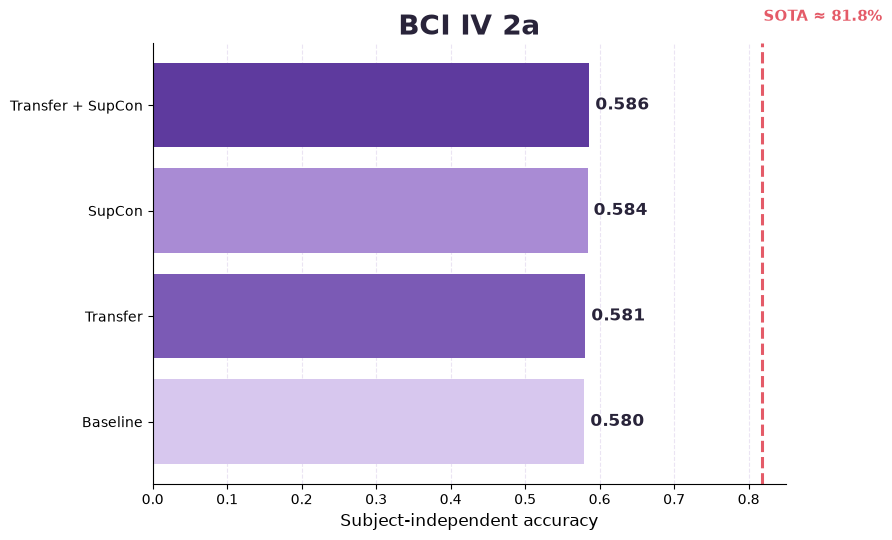

Saved: /Users/irina/Desktop/master project/results_v2/contrastive_subject_independent/plots/bci_supcon.png


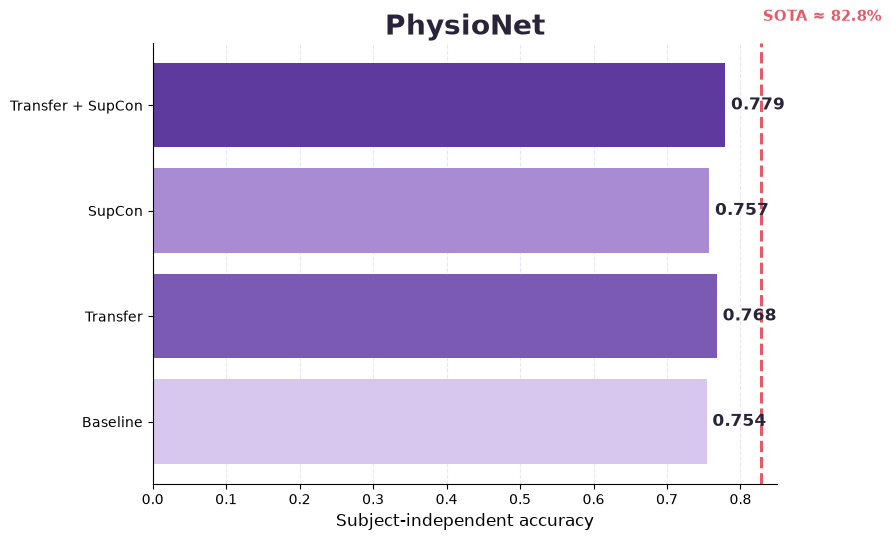

Saved: /Users/irina/Desktop/master project/results_v2/contrastive_subject_independent/plots/physionet_supcon.png

##########################################################################################
FINAL RESULTS
##########################################################################################

BCI


,classifier,mean_accuracy
3,Transfer + SupCon,0.5862
2,SupCon,0.5839
1,Transfer,0.5808
0,Baseline,0.5795



PhysioNet


,classifier,mean_accuracy
7,Transfer + SupCon,0.7791
5,Transfer,0.7678
6,SupCon,0.7574
4,Baseline,0.7538



Saved:
/Users/irina/Desktop/master project/results_v2/contrastive_subject_independent/results/bci_supcon_results.csv
/Users/irina/Desktop/master project/results_v2/contrastive_subject_independent/results/physionet_supcon_results.csv
/Users/irina/Desktop/master project/results_v2/contrastive_subject_independent/results/supcon_summary.csv

SUPCON NIGHT RUN FINISHED


In [10]:
# ============================================================
# 10. NIGHT RUN — SUPCON
#
# BCI:
#   9 folds × 2 models
#
# PhysioNet:
#   5 folds × 2 models
#
# Models:
#   SupCon
#   Transfer + SupCon
#
# AFTER TRAINING:
#   - save CSV
#   - summary tables
#   - combine with previous controls
#   - presentation plots
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# CONFIG
# ============================================================

EPOCHS = 60
PATIENCE = 12

BCI_SUPCON_BATCH = 32
PHYS_SUPCON_BATCH = 16

SUPCON_CONFIGS = [
    ("SupCon", False),
    ("Transfer + SupCon", True),
]


# ============================================================
# PATHS
# ============================================================

BCI_SUPCON_RESULT_PATH = os.path.join(
    SUPCON_RESULT_DIR,
    "bci_supcon_results.csv"
)

PHYS_SUPCON_RESULT_PATH = os.path.join(
    SUPCON_RESULT_DIR,
    "physionet_supcon_results.csv"
)

SUMMARY_PATH = os.path.join(
    SUPCON_RESULT_DIR,
    "supcon_summary.csv"
)


# ============================================================
# BCI
# ============================================================

bci_supcon_results = []

print()
print("#" * 90)
print("START BCI SUPCON")
print("#" * 90)


for split in bci_loso_splits:

    fold = split["fold"]
    test_subject = split["test_subject"]

    print()
    print("=" * 90)
    print(
        f"BCI SUPCON | "
        f"FOLD {fold}/9 | "
        f"TEST={test_subject}"
    )
    print("=" * 90)


    (
        X_train,
        y_train,
        X_val,
        y_val,
        X_test,
        y_test,
        train_mean,
        train_std
    ) = build_bci_loso_fold(
        split
    )


    for model_name, use_transfer in SUPCON_CONFIGS:

        print()
        print("-" * 70)
        print(model_name)
        print("-" * 70)

        set_seed(SEED)

        model = EEGNetSupCon(
            n_channels=22,
            n_classes=4,
            projection_dim=128
        )

        safe_name = (
            model_name
            .lower()
            .replace(" ", "_")
            .replace("+", "plus")
        )

        checkpoint_path = os.path.join(
            SUPCON_MODEL_DIR,
            f"BCI_fold{fold:02d}_{safe_name}.pt"
        )


        (
            model,
            best_epoch,
            best_val
        ) = train_supcon_model(

            model=model,

            subject_data=
                bci_subject_data,

            train_subjects=
                split["train_subjects"],

            X_val=X_val,
            y_val=y_val,

            train_mean=train_mean,
            train_std=train_std,

            checkpoint_path=
                checkpoint_path,

            domain_batch_size=
                BCI_SUPCON_BATCH,

            use_transfer=
                use_transfer
        )


        test_loader = make_loader(
            X_test,
            y_test,
            shuffle=False
        )

        metrics = evaluate_classifier(
            model,
            test_loader
        )


        print(
            f"BEST epoch = {best_epoch}"
        )

        print(
            f"VAL  = {best_val:.4f}"
        )

        print(
            f"TEST = {metrics['accuracy']:.4f}"
        )


        bci_supcon_results.append(
            {
                "dataset":
                    "BCI",

                "fold":
                    fold,

                "test_subject":
                    test_subject,

                "classifier":
                    model_name,

                "best_epoch":
                    best_epoch,

                "val_accuracy":
                    best_val,

                **metrics
            }
        )


        # save immediately
        pd.DataFrame(
            bci_supcon_results
        ).to_csv(
            BCI_SUPCON_RESULT_PATH,
            index=False
        )


        del model

        if DEVICE.type == "mps":
            torch.mps.empty_cache()


print()
print("#" * 90)
print("BCI SUPCON COMPLETE")
print("#" * 90)


# ============================================================
# PHYSIONET
# ============================================================

phys_supcon_results = []

print()
print("#" * 90)
print("START PHYSIONET SUPCON")
print("#" * 90)


for split in phys_folds:

    fold = split["fold"]

    print()
    print("=" * 90)
    print(
        f"PHYSIONET SUPCON | "
        f"FOLD {fold}/5"
    )
    print("=" * 90)


    (
        X_train,
        y_train,
        X_val,
        y_val,
        X_test,
        y_test,
        train_mean,
        train_std
    ) = build_phys_fold(
        split
    )


    for model_name, use_transfer in SUPCON_CONFIGS:

        print()
        print("-" * 70)
        print(model_name)
        print("-" * 70)

        set_seed(SEED)

        model = EEGNetSupCon(
            n_channels=22,
            n_classes=2,
            projection_dim=128
        )

        safe_name = (
            model_name
            .lower()
            .replace(" ", "_")
            .replace("+", "plus")
        )

        checkpoint_path = os.path.join(
            SUPCON_MODEL_DIR,
            f"PHYS_fold{fold:02d}_{safe_name}.pt"
        )


        (
            model,
            best_epoch,
            best_val
        ) = train_supcon_model(

            model=model,

            subject_data=
                phys_subject_data,

            train_subjects=
                split["train_subjects"],

            X_val=X_val,
            y_val=y_val,

            train_mean=train_mean,
            train_std=train_std,

            checkpoint_path=
                checkpoint_path,

            domain_batch_size=
                PHYS_SUPCON_BATCH,

            use_transfer=
                use_transfer
        )


        subject_accs = []


        for subject in split["test_subjects"]:

            X_subject = (
                phys_subject_data[
                    subject
                ]["X"]
                .copy()
            )

            y_subject = (
                phys_subject_data[
                    subject
                ]["y"]
                .copy()
            )


            X_subject = (
                (
                    X_subject
                    - train_mean
                )
                /
                (
                    train_std
                    + 1e-6
                )
            ).astype(
                np.float32
            )


            loader = make_loader(
                X_subject,
                y_subject,
                shuffle=False
            )

            metrics = evaluate_classifier(
                model,
                loader
            )

            subject_accs.append(
                metrics["accuracy"]
            )


            phys_supcon_results.append(
                {
                    "dataset":
                        "PhysioNet",

                    "fold":
                        fold,

                    "test_subject":
                        subject,

                    "classifier":
                        model_name,

                    "best_epoch":
                        best_epoch,

                    "val_accuracy":
                        best_val,

                    **metrics
                }
            )


        print(
            f"TEST subject mean = "
            f"{np.mean(subject_accs):.4f}"
        )


        # save immediately
        pd.DataFrame(
            phys_supcon_results
        ).to_csv(
            PHYS_SUPCON_RESULT_PATH,
            index=False
        )


        del model

        if DEVICE.type == "mps":
            torch.mps.empty_cache()


print()
print("#" * 90)
print("SUPCON TRAINING COMPLETE")
print("#" * 90)


# ============================================================
# LOAD RESULTS
# ============================================================

bci_supcon_df = pd.read_csv(
    BCI_SUPCON_RESULT_PATH
)

phys_supcon_df = pd.read_csv(
    PHYS_SUPCON_RESULT_PATH
)


# ============================================================
# SUMMARY FUNCTION
# ============================================================

def summarize_results(df):

    return (
        df
        .groupby(
            "classifier"
        )
        .agg(
            n_subjects=(
                "test_subject",
                "nunique"
            ),

            mean_accuracy=(
                "accuracy",
                "mean"
            ),

            std_accuracy=(
                "accuracy",
                "std"
            ),

            mean_balanced_accuracy=(
                "balanced_accuracy",
                "mean"
            ),

            mean_macro_f1=(
                "macro_f1",
                "mean"
            ),

            mean_kappa=(
                "kappa",
                "mean"
            )
        )
        .reset_index()
    )


bci_summary = summarize_results(
    bci_supcon_df
)

phys_summary = summarize_results(
    phys_supcon_df
)


print()
print("=" * 90)
print("BCI — SUPCON")
print("=" * 90)

display(
    bci_summary.round(4)
)


print()
print("=" * 90)
print("PHYSIONET — SUPCON")
print("=" * 90)

display(
    phys_summary.round(4)
)


# ============================================================
# COMBINED SUMMARY WITH OLD CONTROLS
# ============================================================

controls = pd.DataFrame(
    [
        {
            "dataset": "BCI",
            "classifier": "Baseline",
            "mean_accuracy": 0.5795
        },
        {
            "dataset": "BCI",
            "classifier": "Transfer",
            "mean_accuracy": 0.5808
        },
        {
            "dataset": "PhysioNet",
            "classifier": "Baseline",
            "mean_accuracy": 0.7538
        },
        {
            "dataset": "PhysioNet",
            "classifier": "Transfer",
            "mean_accuracy": 0.7678
        },
    ]
)


supcon_rows = pd.concat(
    [
        bci_summary[
            [
                "classifier",
                "mean_accuracy"
            ]
        ].assign(
            dataset="BCI"
        ),

        phys_summary[
            [
                "classifier",
                "mean_accuracy"
            ]
        ].assign(
            dataset="PhysioNet"
        )
    ],
    ignore_index=True
)


final_summary = pd.concat(
    [
        controls,
        supcon_rows
    ],
    ignore_index=True
)


model_order = [
    "Baseline",
    "Transfer",
    "SupCon",
    "Transfer + SupCon"
]


final_summary[
    "classifier"
] = pd.Categorical(
    final_summary[
        "classifier"
    ],
    categories=model_order,
    ordered=True
)


final_summary = (
    final_summary
    .sort_values(
        [
            "dataset",
            "classifier"
        ]
    )
    .reset_index(
        drop=True
    )
)


display(
    final_summary.round(4)
)


final_summary.to_csv(
    SUMMARY_PATH,
    index=False
)


# ============================================================
# COLORS
# ============================================================

COLORS = {
    "Baseline": "#D7C7EE",
    "Transfer": "#7B5AB5",
    "SupCon": "#A98BD4",
    "Transfer + SupCon": "#5E3A9E",
}

TEXT = "#29243A"
GRID = "#E9E1F2"

SOTA_COLOR = "#E45B68"

SOTA = {
    "BCI": 0.8179,
    "PhysioNet": 0.8285
}


# ============================================================
# PLOT FUNCTION
# ============================================================

def plot_supcon_summary(
    dataset_name,
    title,
    filename
):

    temp = (
        final_summary[
            final_summary[
                "dataset"
            ]
            == dataset_name
        ]
        .copy()
    )


    temp["classifier"] = pd.Categorical(
        temp["classifier"],
        categories=model_order,
        ordered=True
    )

    temp = temp.sort_values(
        "classifier"
    )


    fig, ax = plt.subplots(
        figsize=(9, 5.5)
    )


    colors = [
        COLORS[str(model)]
        for model in temp[
            "classifier"
        ]
    ]


    bars = ax.barh(
        temp[
            "classifier"
        ].astype(str),

        temp[
            "mean_accuracy"
        ],

        color=colors
    )


    for bar, value in zip(
        bars,
        temp[
            "mean_accuracy"
        ]
    ):

        ax.text(
            value + 0.008,
            bar.get_y()
            + bar.get_height() / 2,

            f"{value:.3f}",

            va="center",
            ha="left",

            fontsize=12,
            fontweight="bold",
            color=TEXT
        )


    sota = SOTA[
        dataset_name
    ]

    ax.axvline(
        sota,
        linestyle="--",
        linewidth=2.2,
        color=SOTA_COLOR
    )

    ax.text(
        sota + 0.002,
        len(temp) - 0.2,

        f"SOTA ≈ "
        f"{sota * 100:.1f}%",

        fontsize=11,
        fontweight="bold",
        color=SOTA_COLOR
    )


    ax.set_xlim(
        0,
        0.85
    )

    ax.set_title(
        title,
        fontsize=20,
        fontweight="bold",
        color=TEXT
    )

    ax.set_xlabel(
        "Subject-independent accuracy",
        fontsize=12
    )

    ax.grid(
        axis="x",
        linestyle="--",
        color=GRID,
        alpha=0.9
    )

    ax.set_axisbelow(
        True
    )

    ax.spines[
        "top"
    ].set_visible(False)

    ax.spines[
        "right"
    ].set_visible(False)

    plt.tight_layout()


    path = os.path.join(
        SUPCON_PLOT_DIR,
        filename
    )

    plt.savefig(
        path,
        dpi=220,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()

    print(
        "Saved:",
        path
    )


# ============================================================
# PLOTS
# ============================================================

plot_supcon_summary(
    dataset_name="BCI",
    title="BCI IV 2a",
    filename="bci_supcon.png"
)


plot_supcon_summary(
    dataset_name="PhysioNet",
    title="PhysioNet",
    filename="physionet_supcon.png"
)


# ============================================================
# FINAL
# ============================================================

print()
print("#" * 90)
print("FINAL RESULTS")
print("#" * 90)


for dataset_name in [
    "BCI",
    "PhysioNet"
]:

    temp = (
        final_summary[
            final_summary[
                "dataset"
            ]
            == dataset_name
        ]
        .sort_values(
            "mean_accuracy",
            ascending=False
        )
    )

    print()
    print(dataset_name)

    display(
        temp[
            [
                "classifier",
                "mean_accuracy"
            ]
        ].round(4)
    )


print()
print("Saved:")
print(
    BCI_SUPCON_RESULT_PATH
)
print(
    PHYS_SUPCON_RESULT_PATH
)
print(
    SUMMARY_PATH
)

print()
print(
    "SUPCON NIGHT RUN FINISHED"
)

In [13]:
# ============================================================
# 11. SUPCON STATISTICS
# SupCon vs Transfer + SupCon
# WITHOUT STATSMODELS
# ============================================================

import numpy as np
import pandas as pd

from scipy.stats import wilcoxon


# ------------------------------------------------------------
# BOOTSTRAP 95% CI
# ------------------------------------------------------------

def bootstrap_mean_ci(
    differences,
    n_boot=10000,
    seed=42
):
    rng = np.random.default_rng(seed)

    differences = np.asarray(
        differences,
        dtype=float
    )

    boot_means = np.empty(
        n_boot,
        dtype=float
    )

    for i in range(n_boot):

        sample = rng.choice(
            differences,
            size=len(differences),
            replace=True
        )

        boot_means[i] = sample.mean()

    ci_low, ci_high = np.percentile(
        boot_means,
        [2.5, 97.5]
    )

    return ci_low, ci_high


# ------------------------------------------------------------
# HOLM CORRECTION
# ------------------------------------------------------------

def holm_correction(
    p_values,
    alpha=0.05
):
    p_values = np.asarray(
        p_values,
        dtype=float
    )

    order = np.argsort(
        p_values
    )

    sorted_p = p_values[
        order
    ]

    m = len(
        p_values
    )

    adjusted_sorted = np.empty(
        m,
        dtype=float
    )

    running_max = 0.0

    for i, p in enumerate(
        sorted_p
    ):

        adjusted = (
            (m - i)
            * p
        )

        running_max = max(
            running_max,
            adjusted
        )

        adjusted_sorted[i] = min(
            running_max,
            1.0
        )

    adjusted = np.empty(
        m,
        dtype=float
    )

    adjusted[
        order
    ] = adjusted_sorted

    reject = (
        adjusted < alpha
    )

    return (
        reject,
        adjusted
    )


# ------------------------------------------------------------
# ONE DATASET COMPARISON
# ------------------------------------------------------------

def compare_supcon_transfer(
    df,
    dataset_name
):

    pivot = (
        df
        .pivot(
            index="test_subject",
            columns="classifier",
            values="accuracy"
        )
        .dropna(
            subset=[
                "SupCon",
                "Transfer + SupCon"
            ]
        )
    )

    supcon = pivot[
        "SupCon"
    ].values

    transfer_supcon = pivot[
        "Transfer + SupCon"
    ].values

    differences = (
        transfer_supcon
        - supcon
    )


    # --------------------------------------------------------
    # WILCOXON
    # --------------------------------------------------------

    try:

        stat, p_value = wilcoxon(
            transfer_supcon,
            supcon,
            alternative="two-sided"
        )

    except ValueError:

        stat = np.nan
        p_value = np.nan


    # --------------------------------------------------------
    # BOOTSTRAP CI
    # --------------------------------------------------------

    ci_low, ci_high = bootstrap_mean_ci(
        differences,
        n_boot=10000,
        seed=42
    )


    return {

        "dataset":
            dataset_name,

        "n_subjects":
            len(differences),

        "supcon_mean":
            supcon.mean(),

        "transfer_supcon_mean":
            transfer_supcon.mean(),

        "gain_pp":
            differences.mean() * 100,

        "ci_low_pp":
            ci_low * 100,

        "ci_high_pp":
            ci_high * 100,

        "better":
            int(
                (
                    differences > 0
                ).sum()
            ),

        "equal":
            int(
                (
                    differences == 0
                ).sum()
            ),

        "worse":
            int(
                (
                    differences < 0
                ).sum()
            ),

        "wilcoxon_stat":
            stat,

        "wilcoxon_p":
            p_value
    }


# ------------------------------------------------------------
# BCI + PHYSIONET
# ------------------------------------------------------------

stats_rows = [

    compare_supcon_transfer(
        bci_supcon_df,
        "BCI IV 2a"
    ),

    compare_supcon_transfer(
        phys_supcon_df,
        "PhysioNet"
    )
]


supcon_stats_df = pd.DataFrame(
    stats_rows
)


# ------------------------------------------------------------
# HOLM CORRECTION
# ------------------------------------------------------------

reject, p_holm = holm_correction(
    supcon_stats_df[
        "wilcoxon_p"
    ].values,
    alpha=0.05
)

supcon_stats_df[
    "p_holm"
] = p_holm

supcon_stats_df[
    "significant_holm"
] = reject


# ------------------------------------------------------------
# DISPLAY
# ------------------------------------------------------------

display(
    supcon_stats_df.round(6)
)

,dataset,n_subjects,supcon_mean,transfer_supcon_mean,gain_pp,ci_low_pp,ci_high_pp,better,equal,worse,wilcoxon_stat,wilcoxon_p,p_holm,significant_holm
0,BCI IV 2a,9,0.583912,0.586227,0.231481,-1.909722,1.967593,6,0,3,17.0,0.570312,0.570312,False
1,PhysioNet,106,0.757364,0.779119,2.175418,0.933645,3.454244,58,19,29,1178.0,0.001811,0.003623,True


In [14]:
# ============================================================
# 12. BCI SUBJECT-WISE SUPCON EFFECT
# ============================================================

bci_supcon_subjects = (
    bci_supcon_df
    .pivot(
        index="test_subject",
        columns="classifier",
        values="accuracy"
    )
    .reset_index()
)

bci_supcon_subjects[
    "transfer_gain_pp"
] = (
    (
        bci_supcon_subjects[
            "Transfer + SupCon"
        ]
        -
        bci_supcon_subjects[
            "SupCon"
        ]
    )
    * 100
)

display(
    bci_supcon_subjects.round(4)
)

classifier,test_subject,SupCon,Transfer + SupCon,transfer_gain_pp
0,A01,0.6736,0.6927,1.9097
1,A02,0.4288,0.4583,2.9514
2,A03,0.7517,0.7708,1.9097
3,A04,0.4375,0.4427,0.5208
4,A05,0.4913,0.4653,-2.6042
5,A06,0.5035,0.5226,1.9097
6,A07,0.6944,0.6302,-6.4236
7,A08,0.6649,0.6979,3.2986
8,A09,0.6094,0.5955,-1.3889


# Вывод

Supervised Contrastive Learning показал различный эффект на двух датасетах.

## BCI IV 2a

Transfer + SupCon дал небольшой прирост относительно SupCon:

- 0.5839 → 0.5862;
- +0.23 п.п.;
- улучшение у 6 из 9 subjects.

Однако 95% bootstrap CI включает ноль
([-1.91; +1.97] п.п.), а Wilcoxon test не показал
статистически значимого различия
(p = 0.5703).

Следовательно, для BCI IV 2a эффект Transfer + SupCon
можно рассматривать только как слабый положительный тренд.

## PhysioNet

На PhysioNet добавление Cho transfer к SupCon
дало более выраженный эффект:

- 0.7574 → 0.7791;
- +2.18 п.п.;
- 95% CI [+0.93; +3.45] п.п.;
- улучшение у 58 из 106 subjects;
- Wilcoxon p = 0.0018;
- Holm-adjusted p = 0.0036.

Таким образом, на PhysioNet комбинация pretrained EEG representation
и supervised contrastive learning дала статистически значимое
улучшение subject-independent classification.

## Общий вывод

Contrastive learning оказался более перспективным,
чем CORAL, MMD и DANN для BCI IV 2a,
однако достигнутый прирост пока статистически не подтверждён.

На PhysioNet Transfer + SupCon дал устойчивое и статистически
значимое улучшение и стал одним из лучших вариантов модели.

In [15]:
# ============================================================
# 13. DOES SUPCON ADD VALUE ON TOP OF CHO TRANSFER?
#
# Transfer
#     vs
# Transfer + SupCon
#
# BCI IV 2a + PhysioNet
# ============================================================

import os
from pathlib import Path

import numpy as np
import pandas as pd

from scipy.stats import wilcoxon


# ============================================================
# HELPERS
# ============================================================

def bootstrap_mean_ci(
    differences,
    n_boot=10000,
    seed=42
):
    rng = np.random.default_rng(seed)

    differences = np.asarray(
        differences,
        dtype=float
    )

    boot_means = np.empty(
        n_boot
    )

    for i in range(n_boot):

        sample = rng.choice(
            differences,
            size=len(differences),
            replace=True
        )

        boot_means[i] = (
            sample.mean()
        )

    return np.percentile(
        boot_means,
        [2.5, 97.5]
    )


def holm_correction(
    p_values,
    alpha=0.05
):
    p_values = np.asarray(
        p_values,
        dtype=float
    )

    order = np.argsort(
        p_values
    )

    sorted_p = p_values[
        order
    ]

    m = len(p_values)

    adjusted_sorted = np.empty(
        m,
        dtype=float
    )

    running_max = 0.0

    for i, p in enumerate(
        sorted_p
    ):

        adjusted = (
            (m - i)
            * p
        )

        running_max = max(
            running_max,
            adjusted
        )

        adjusted_sorted[i] = min(
            running_max,
            1.0
        )

    adjusted = np.empty(
        m,
        dtype=float
    )

    adjusted[
        order
    ] = adjusted_sorted

    reject = (
        adjusted < alpha
    )

    return (
        reject,
        adjusted
    )


# ============================================================
# FIND OLD SUBJECT-LEVEL TRANSFER RESULTS
# ============================================================

def find_old_transfer_results(
    dataset_name,
    expected_subjects
):

    search_root = Path(
        BASE_DIR
    ) / "results_v2"

    candidates = []


    for path in search_root.rglob(
        "*.csv"
    ):

        # Do not accidentally use current SupCon result
        if (
            "contrastive_subject_independent"
            in str(path)
        ):
            continue

        try:

            df = pd.read_csv(
                path
            )

        except Exception:

            continue


        required = {
            "test_subject",
            "classifier",
            "accuracy"
        }

        if not required.issubset(
            df.columns
        ):
            continue


        transfer = df[
            df["classifier"]
            == "Transfer"
        ].copy()


        if len(transfer) == 0:
            continue


        n_subjects = (
            transfer[
                "test_subject"
            ]
            .nunique()
        )


        if (
            n_subjects
            != expected_subjects
        ):
            continue


        # Score filenames so BCI files prefer "bci"
        # and PhysioNet files prefer "phys"
        name = str(path).lower()

        score = 0

        if dataset_name == "BCI":

            if "bci" in name:
                score += 10

            if "strict" in name:
                score += 5

            if "loso" in name:
                score += 5

            if "fixed" in name:
                score += 3

        if dataset_name == "PhysioNet":

            if "phys" in name:
                score += 10

            if "subject_independent" in name:
                score += 5


        candidates.append(
            (
                score,
                path,
                transfer
            )
        )


    if not candidates:

        raise FileNotFoundError(
            f"No old Transfer results found "
            f"for {dataset_name}"
        )


    candidates.sort(
        key=lambda x: x[0],
        reverse=True
    )


    best_score, best_path, best_df = (
        candidates[0]
    )


    print()
    print(
        dataset_name,
        "old Transfer file:"
    )

    print(
        best_path
    )

    print(
        "Subjects:",
        best_df[
            "test_subject"
        ].nunique()
    )


    return (
        best_df,
        best_path
    )


# ============================================================
# LOAD OLD TRANSFER
# ============================================================

bci_transfer_old, bci_old_path = (
    find_old_transfer_results(
        dataset_name="BCI",
        expected_subjects=9
    )
)


phys_transfer_old, phys_old_path = (
    find_old_transfer_results(
        dataset_name="PhysioNet",
        expected_subjects=106
    )
)


# ============================================================
# PREPARE NEW TRANSFER + SUPCON
# ============================================================

bci_transfer_supcon = (
    bci_supcon_df[
        bci_supcon_df[
            "classifier"
        ]
        == "Transfer + SupCon"
    ][
        [
            "test_subject",
            "accuracy"
        ]
    ]
    .rename(
        columns={
            "accuracy":
                "Transfer + SupCon"
        }
    )
)


phys_transfer_supcon = (
    phys_supcon_df[
        phys_supcon_df[
            "classifier"
        ]
        == "Transfer + SupCon"
    ][
        [
            "test_subject",
            "accuracy"
        ]
    ]
    .rename(
        columns={
            "accuracy":
                "Transfer + SupCon"
        }
    )
)


# ============================================================
# PREPARE OLD TRANSFER
# ============================================================

bci_transfer = (
    bci_transfer_old[
        [
            "test_subject",
            "accuracy"
        ]
    ]
    .rename(
        columns={
            "accuracy":
                "Transfer"
        }
    )
)


phys_transfer = (
    phys_transfer_old[
        [
            "test_subject",
            "accuracy"
        ]
    ]
    .rename(
        columns={
            "accuracy":
                "Transfer"
        }
    )
)


# ============================================================
# MERGE EXACTLY BY SUBJECT
# ============================================================

bci_comparison = (
    bci_transfer
    .merge(
        bci_transfer_supcon,
        on="test_subject",
        how="inner"
    )
    .sort_values(
        "test_subject"
    )
    .reset_index(
        drop=True
    )
)


phys_comparison = (
    phys_transfer
    .merge(
        phys_transfer_supcon,
        on="test_subject",
        how="inner"
    )
    .sort_values(
        "test_subject"
    )
    .reset_index(
        drop=True
    )
)


assert len(
    bci_comparison
) == 9

assert len(
    phys_comparison
) == 106


# ============================================================
# STATISTICS FUNCTION
# ============================================================

def compare_with_transfer(
    comparison,
    dataset_name
):

    transfer = (
        comparison[
            "Transfer"
        ]
        .values
    )

    supcon = (
        comparison[
            "Transfer + SupCon"
        ]
        .values
    )

    diff = (
        supcon
        - transfer
    )


    stat, p_value = wilcoxon(
        supcon,
        transfer,
        alternative="two-sided"
    )


    ci_low, ci_high = (
        bootstrap_mean_ci(
            diff,
            n_boot=10000,
            seed=42
        )
    )


    return {

        "dataset":
            dataset_name,

        "n_subjects":
            len(diff),

        "transfer_mean":
            transfer.mean(),

        "transfer_supcon_mean":
            supcon.mean(),

        "gain_pp":
            diff.mean() * 100,

        "ci_low_pp":
            ci_low * 100,

        "ci_high_pp":
            ci_high * 100,

        "better":
            int(
                (diff > 0).sum()
            ),

        "equal":
            int(
                (diff == 0).sum()
            ),

        "worse":
            int(
                (diff < 0).sum()
            ),

        "wilcoxon_stat":
            stat,

        "wilcoxon_p":
            p_value
    }


# ============================================================
# BCI + PHYSIONET
# ============================================================

transfer_supcon_stats = pd.DataFrame(
    [

        compare_with_transfer(
            bci_comparison,
            "BCI IV 2a"
        ),

        compare_with_transfer(
            phys_comparison,
            "PhysioNet"
        )
    ]
)


# ============================================================
# HOLM
# ============================================================

reject, p_holm = holm_correction(
    transfer_supcon_stats[
        "wilcoxon_p"
    ].values
)


transfer_supcon_stats[
    "p_holm"
] = p_holm

transfer_supcon_stats[
    "significant_holm"
] = reject


# ============================================================
# RESULTS
# ============================================================

display(
    transfer_supcon_stats.round(6)
)


BCI old Transfer file:
/Users/irina/Desktop/master project/results_v2/subject_independent_transfer_denoising/results/bci_strict_loso_clean_fixed.csv
Subjects: 9

PhysioNet old Transfer file:
/Users/irina/Desktop/master project/results_v2/subject_independent_transfer_denoising/results/physionet_subject_independent_clean.csv
Subjects: 106


,dataset,n_subjects,transfer_mean,transfer_supcon_mean,gain_pp,ci_low_pp,ci_high_pp,better,equal,worse,wilcoxon_stat,wilcoxon_p,p_holm,significant_holm
0,BCI IV 2a,9,0.580826,0.586227,0.540123,-0.925926,2.083333,5,0,4,18.0,0.652344,0.652344,False
1,PhysioNet,106,0.767817,0.779119,1.130125,0.209644,2.050656,49,20,37,1396.5,0.040549,0.081099,False


In [16]:
# ============================================================
# 14. BCI:
# TRANSFER vs TRANSFER + SUPCON BY SUBJECT
# ============================================================

bci_comparison[
    "supcon_gain_pp"
] = (
    (
        bci_comparison[
            "Transfer + SupCon"
        ]
        -
        bci_comparison[
            "Transfer"
        ]
    )
    * 100
)

display(
    bci_comparison.round(4)
)

,test_subject,Transfer,Transfer + SupCon,supcon_gain_pp
0,A01,0.6580,0.6927,3.4722
1,A02,0.4497,0.4583,0.8681
2,A03,0.7569,0.7708,1.3889
3,A04,0.4566,0.4427,-1.3889
4,A05,0.4965,0.4653,-3.1250
5,A06,0.5122,0.5226,1.0417
6,A07,0.5851,0.6302,4.5139
7,A08,0.6997,0.6979,-0.1736
8,A09,0.6128,0.5955,-1.7361


# Статистический вывод: добавляет ли SupCon эффект поверх Cho Transfer?

## BCI IV 2a

Сравнение обычного Cho Transfer и Transfer + SupCon:

- Transfer: 0.5808
- Transfer + SupCon: 0.5862
- прирост: +0.54 п.п.
- 95% bootstrap CI: [-0.93; +2.08] п.п.
- лучше: 5 из 9 subjects
- хуже: 4 из 9 subjects
- Wilcoxon p = 0.6523
- Holm-adjusted p = 0.6523

Таким образом, на BCI IV 2a добавление supervised contrastive loss
к Cho-pretrained EEGNet не дало статистически подтверждённого улучшения.

Среднее значение стало немного выше, однако эффект нестабилен
между subjects.

---

## PhysioNet

Сравнение обычного Cho Transfer и Transfer + SupCon:

- Transfer: 0.7678
- Transfer + SupCon: 0.7791
- прирост: +1.13 п.п.
- 95% bootstrap CI: [+0.21; +2.05] п.п.
- лучше: 49 из 106 subjects
- без изменений: 20
- хуже: 37
- Wilcoxon p = 0.0405
- Holm-adjusted p = 0.0811

На PhysioNet наблюдается устойчивый положительный средний эффект:
bootstrap confidence interval не включает ноль.

Однако после поправки Holm результат не достигает уровня
статистической значимости 0.05.

Поэтому результат следует интерпретировать как положительный сигнал,
но не как окончательно доказанное преимущество Transfer + SupCon
над обычным Transfer.

---

## Общий вывод

Supervised Contrastive Learning оказался наиболее перспективным
из протестированных дополнительных objectives для BCI IV 2a,
но пока не позволил статистически надёжно превысить обычный Transfer.

На PhysioNet эффект выражен сильнее:
Transfer + SupCon улучшает среднюю accuracy примерно на 1.1 п.п.,
однако после correction for multiple comparisons доказательств
недостаточно для строгого утверждения о превосходстве.

In [17]:
# ============================================================
# LOAD OLD PHYSIONET CORAL / MMD RESULTS
# ============================================================

OLD_DG_PATH = (
    "/Users/irina/Desktop/master project/"
    "results_v2/domain_generalization/results/"
    "physionet_dg_results.csv"
)

phys_old_dg = pd.read_csv(
    OLD_DG_PATH
)

print(
    phys_old_dg["classifier"].value_counts()
)

display(
    phys_old_dg.head()
)

classifier
CORAL               106
Transfer + CORAL    106
MMD                 106
Transfer + MMD      106
Name: count, dtype: int64


,dataset,fold,test_subject,classifier,best_epoch,val_accuracy,accuracy,balanced_accuracy,macro_f1,kappa
0,PhysioNet,1,S001,CORAL,59,0.803922,0.777778,0.777668,0.777668,0.555336
1,PhysioNet,1,S005,CORAL,59,0.803922,0.600000,0.604167,0.599802,0.205882
2,PhysioNet,1,S011,CORAL,59,0.803922,0.644444,0.641304,0.635628,0.284294
3,PhysioNet,1,S012,CORAL,59,0.803922,0.733333,0.744048,0.730000,0.476744
4,PhysioNet,1,S013,CORAL,59,0.803922,0.777778,0.775692,0.775000,0.553571


In [18]:
# ============================================================
# 18. PHYSIONET:
# TRANSFER + SUPCON
# vs TRANSFER + CORAL / TRANSFER + MMD
# ============================================================

import numpy as np
import pandas as pd

from scipy.stats import wilcoxon


# ------------------------------------------------------------
# HELPERS
# ------------------------------------------------------------

def bootstrap_mean_ci(
    differences,
    n_boot=10000,
    seed=42
):
    rng = np.random.default_rng(seed)

    differences = np.asarray(
        differences,
        dtype=float
    )

    boot_means = np.empty(
        n_boot,
        dtype=float
    )

    for i in range(n_boot):

        sample = rng.choice(
            differences,
            size=len(differences),
            replace=True
        )

        boot_means[i] = (
            sample.mean()
        )

    return np.percentile(
        boot_means,
        [2.5, 97.5]
    )


def holm_correction(
    p_values,
    alpha=0.05
):
    p_values = np.asarray(
        p_values,
        dtype=float
    )

    order = np.argsort(
        p_values
    )

    sorted_p = p_values[
        order
    ]

    m = len(p_values)

    adjusted_sorted = np.empty(
        m,
        dtype=float
    )

    running_max = 0.0

    for i, p in enumerate(
        sorted_p
    ):

        adjusted = (
            (m - i)
            * p
        )

        running_max = max(
            running_max,
            adjusted
        )

        adjusted_sorted[i] = min(
            running_max,
            1.0
        )

    adjusted = np.empty(
        m,
        dtype=float
    )

    adjusted[
        order
    ] = adjusted_sorted

    reject = (
        adjusted < alpha
    )

    return (
        reject,
        adjusted
    )


# ------------------------------------------------------------
# CURRENT TRANSFER + SUPCON
# ------------------------------------------------------------

supcon_df = (
    phys_supcon_df[
        phys_supcon_df[
            "classifier"
        ]
        == "Transfer + SupCon"
    ][
        [
            "test_subject",
            "accuracy"
        ]
    ]
    .rename(
        columns={
            "accuracy":
                "Transfer + SupCon"
        }
    )
)


# ------------------------------------------------------------
# OLD TRANSFER + CORAL
# ------------------------------------------------------------

coral_df = (
    phys_old_dg[
        phys_old_dg[
            "classifier"
        ]
        == "Transfer + CORAL"
    ][
        [
            "test_subject",
            "accuracy"
        ]
    ]
    .rename(
        columns={
            "accuracy":
                "Transfer + CORAL"
        }
    )
)


# ------------------------------------------------------------
# OLD TRANSFER + MMD
# ------------------------------------------------------------

mmd_df = (
    phys_old_dg[
        phys_old_dg[
            "classifier"
        ]
        == "Transfer + MMD"
    ][
        [
            "test_subject",
            "accuracy"
        ]
    ]
    .rename(
        columns={
            "accuracy":
                "Transfer + MMD"
        }
    )
)


# ------------------------------------------------------------
# MERGE BY SUBJECT
# ------------------------------------------------------------

comparison = (
    supcon_df
    .merge(
        coral_df,
        on="test_subject",
        how="inner"
    )
    .merge(
        mmd_df,
        on="test_subject",
        how="inner"
    )
    .sort_values(
        "test_subject"
    )
    .reset_index(
        drop=True
    )
)


print(
    "Subjects:",
    len(comparison)
)

assert (
    len(comparison) == 106
)


# ------------------------------------------------------------
# PAIRWISE COMPARISON
# ------------------------------------------------------------

def compare_models(
    comparison,
    reference_name,
    new_name="Transfer + SupCon"
):

    reference = (
        comparison[
            reference_name
        ].values
    )

    new = (
        comparison[
            new_name
        ].values
    )

    diff = (
        new
        - reference
    )


    stat, p_value = wilcoxon(
        new,
        reference,
        alternative="two-sided"
    )


    ci_low, ci_high = (
        bootstrap_mean_ci(
            diff,
            n_boot=10000,
            seed=42
        )
    )


    return {

        "comparison":
            f"{new_name} vs {reference_name}",

        "reference_mean":
            reference.mean(),

        "supcon_mean":
            new.mean(),

        "gain_pp":
            diff.mean() * 100,

        "ci_low_pp":
            ci_low * 100,

        "ci_high_pp":
            ci_high * 100,

        "better":
            int(
                (diff > 0).sum()
            ),

        "equal":
            int(
                (diff == 0).sum()
            ),

        "worse":
            int(
                (diff < 0).sum()
            ),

        "wilcoxon_stat":
            stat,

        "wilcoxon_p":
            p_value
    }


rows = [

    compare_models(
        comparison,
        "Transfer + CORAL"
    ),

    compare_models(
        comparison,
        "Transfer + MMD"
    )
]


supcon_vs_dg_stats = pd.DataFrame(
    rows
)


# ------------------------------------------------------------
# HOLM CORRECTION
# ------------------------------------------------------------

reject, p_holm = holm_correction(
    supcon_vs_dg_stats[
        "wilcoxon_p"
    ].values,
    alpha=0.05
)


supcon_vs_dg_stats[
    "p_holm"
] = p_holm

supcon_vs_dg_stats[
    "significant_holm"
] = reject


# ------------------------------------------------------------
# DISPLAY
# ------------------------------------------------------------

display(
    supcon_vs_dg_stats.round(6)
)

Subjects: 106


,comparison,reference_mean,supcon_mean,gain_pp,ci_low_pp,ci_high_pp,better,equal,worse,wilcoxon_stat,wilcoxon_p,p_holm,significant_holm
0,Transfer + SupCon vs Transfer + CORAL,0.778728,0.779119,0.039003,-0.937217,1.027254,38,20,48,1844.5,0.910616,1.0,False
1,Transfer + SupCon vs Transfer + MMD,0.776622,0.779119,0.249622,-0.777632,1.278826,49,13,44,2033.5,0.559491,1.0,False


# Сравнение Transfer + SupCon с другими лучшими DG-моделями

На PhysioNet Transfer + SupCon показал максимальную среднюю accuracy
среди рассматриваемых моделей:

- Transfer + CORAL: 0.7787
- Transfer + MMD: 0.7766
- Transfer + SupCon: 0.7791

Однако различия между этими моделями статистически не подтверждены.

## Transfer + SupCon vs Transfer + CORAL

- прирост: +0.04 п.п.
- 95% bootstrap CI: [-0.94; +1.03] п.п.
- Wilcoxon p = 0.911
- Holm-adjusted p = 1.0

## Transfer + SupCon vs Transfer + MMD

- прирост: +0.25 п.п.
- 95% bootstrap CI: [-0.78; +1.28] п.п.
- Wilcoxon p = 0.559
- Holm-adjusted p = 1.0

Таким образом, Transfer + SupCon численно показал лучший результат,
но его преимущество над Transfer + CORAL и Transfer + MMD
не является статистически значимым.

На PhysioNet три подхода можно рассматривать как модели одного уровня,
при этом основной устойчивый фактор улучшения — Cho pretraining.